# Notebook 2 · Exploratory Data Analysis (Team Delta · LeakLens · The Money Leak)

**Purpose:** understand the business and find where money leaks, using the cleaned data from Notebook 1.
Each section asks **one question**, shows a chart or table, and ends with a prompt for what to write in your report.

**Sections**
0. Setup and load the cleaned data
1. Build the master table and the headline numbers
2. The data, one column at a time
3. What happens to orders?
4. Time patterns
5. Where do orders fail?
6. Discounts
7. Products and categories
8. Customers
9. Channels
10. Marketing
11. Inventory
12. Correlations
13. Summary of findings

> **Currency:** not stated in the dataset, so amounts are plain numbers. Pick one currency for the report.

## Step 0 · Setup and load the cleaned data
Upload **cleaned_data.zip** (created at the end of Notebook 1).

In [55]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 50
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

DATA = "../data"   # notebook is inside notebooks/

customers    = pd.read_csv(f"{DATA}/customers.csv",    parse_dates=["signup_date"])
products     = pd.read_csv(f"{DATA}/products.csv")
transactions = pd.read_csv(f"{DATA}/transactions.csv", parse_dates=["timestamp"])
inventory    = pd.read_csv(f"{DATA}/inventory.csv",    parse_dates=["date"])
campaigns    = pd.read_csv(f"{DATA}/campaigns.csv",    parse_dates=["date"])

for n, d in dict(
    customers=customers,
    products=products,
    transactions=transactions,
    inventory=inventory,
    campaigns=campaigns
).items():
    print(f"{n:13s} {d.shape}")

customers     (3000, 5)
products      (250, 5)
transactions  (18000, 10)
inventory     (5000, 7)
campaigns     (1200, 8)


## Step 1 · Master table and headline numbers
One row per order, with product and customer details attached.

**Definitions (put these in your report)**
- `net_sales = quantity × unit_price × (1 − discount_pct)`
- `cost = quantity × unit_cost`  |  `profit = net_sales − cost`
- Sales and profit count **Completed** orders only. Cancelled, Returned and Pending orders are order value that did not become a sale.

In [56]:
df = transactions.merge(products, on="product_id", how="left").merge(customers, on="customer_id", how="left")
df["net_sales"]    = df.quantity * df.unit_price * (1 - df.discount_pct)
df["cost"]         = df.quantity * df.unit_cost
df["profit"]       = df.net_sales - df.cost
df["margin"]       = df.profit / df.net_sales
df["discount_amt"] = df.quantity * df.unit_price * df.discount_pct
df["month"]        = df.timestamp.dt.to_period("M").dt.to_timestamp()
df["dow"]          = df.timestamp.dt.day_name()
df["hour"]         = df.timestamp.dt.hour
df["tenure_days"]  = (df.timestamp - df.signup_date).dt.days
df["is_completed"] = df.status.eq("Completed")
df["is_failed"]    = df.status.isin(["Cancelled", "Returned"])
df["is_loss"]      = df.is_completed & (df.profit < 0)
comp = df[df.is_completed].copy()
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

kpi = {
    "Orders": len(df), "Customers who ordered": df.customer_id.nunique(), "Products sold": df.product_id.nunique(),
    "Total order value": df.net_sales.sum(), "Completed sales": comp.net_sales.sum(), "Completed profit": comp.profit.sum(),
    "Profit margin": comp.profit.sum() / comp.net_sales.sum(),
    "Order value not completed": df[~df.is_completed].net_sales.sum(),
    "  as share of total": df[~df.is_completed].net_sales.sum() / df.net_sales.sum(),
    "Completed sales that lose money": comp.is_loss.mean(), "Average order value (completed)": comp.net_sales.mean()}
display(pd.Series(kpi, name="value").to_frame())

,value
Orders,"18,000.00"
Customers who ordered,"2,987.00"
Products sold,250.00
Total order value,"9,390,803.10"
Completed sales,"7,301,698.25"
Completed profit,"1,968,988.40"
Profit margin,0.27
Order value not completed,"2,089,104.85"
as share of total,0.22
Completed sales that lose money,0.38


**Write:** one sentence on size (orders, customers, products) and one on the headline problem (share of order value that never completes, share of sales that lose money).

## Step 2 · The data, one column at a time (univariate analysis)
Question: what does each important column look like by itself?

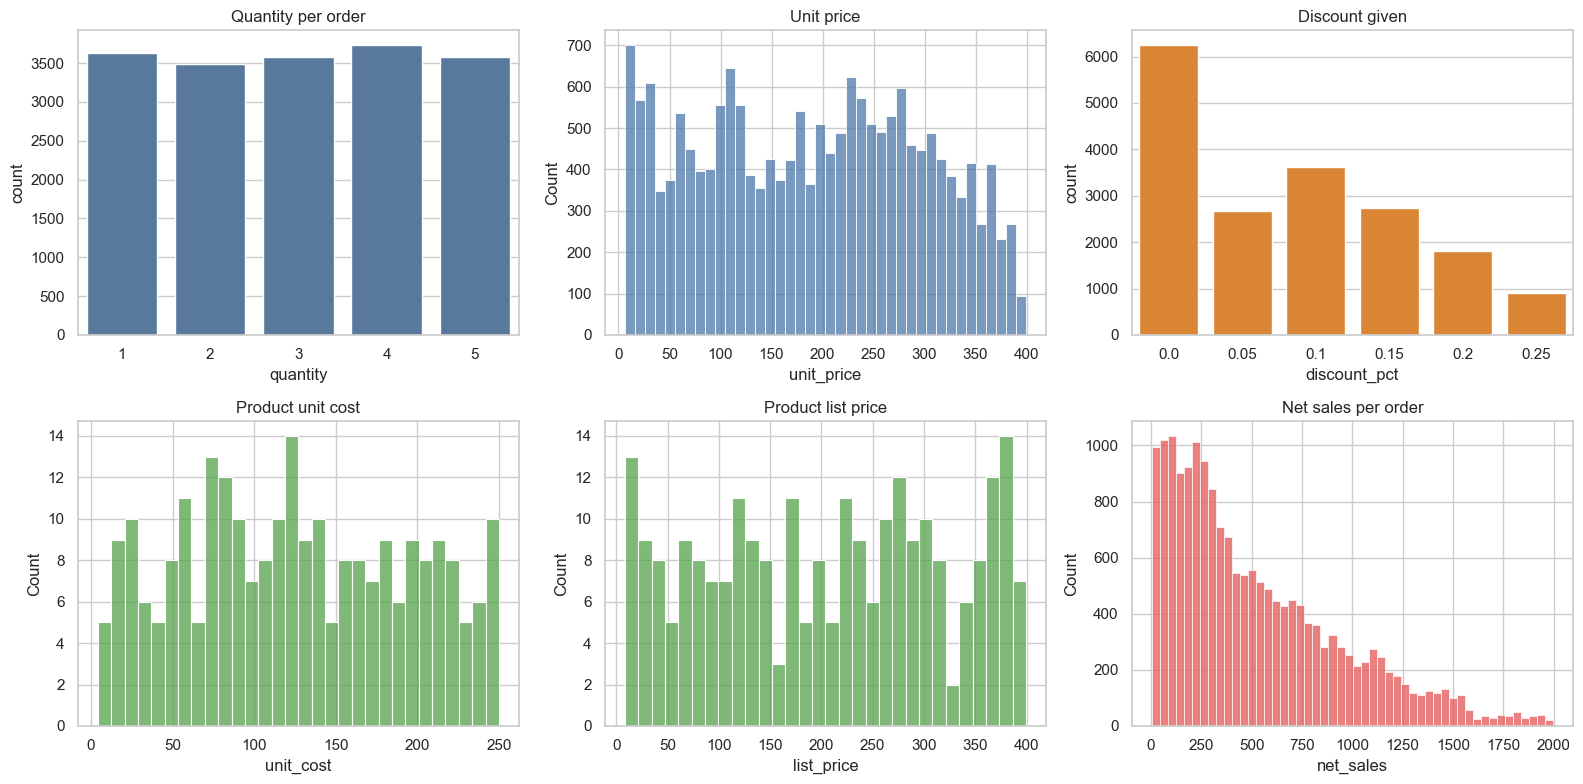

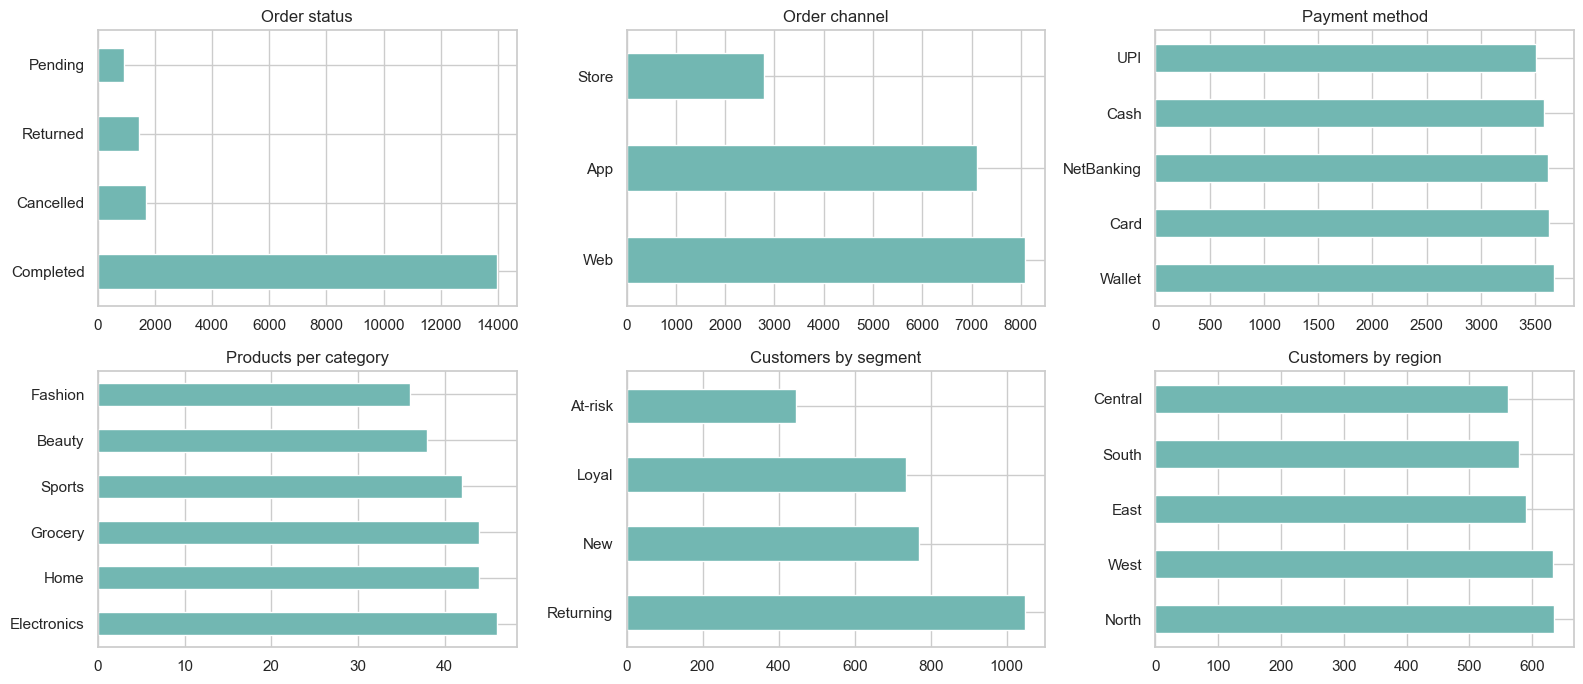

In [57]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sns.countplot(data=df, x="quantity", ax=ax[0, 0], color="#4c78a8"); ax[0, 0].set_title("Quantity per order")
sns.histplot(df.unit_price, bins=40, ax=ax[0, 1], color="#4c78a8"); ax[0, 1].set_title("Unit price")
sns.countplot(data=df, x="discount_pct", ax=ax[0, 2], color="#f58518"); ax[0, 2].set_title("Discount given")
sns.histplot(products.unit_cost, bins=30, ax=ax[1, 0], color="#54a24b"); ax[1, 0].set_title("Product unit cost")
sns.histplot(products.list_price, bins=30, ax=ax[1, 1], color="#54a24b"); ax[1, 1].set_title("Product list price")
sns.histplot(df.net_sales, bins=50, ax=ax[1, 2], color="#e45756"); ax[1, 2].set_title("Net sales per order")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a, (col, d, t) in zip(ax.ravel(), [("status", df, "Order status"), ("channel", df, "Order channel"), ("payment_method", df, "Payment method"),
                                       ("category", products, "Products per category"), ("customer_segment", customers, "Customers by segment"), ("region", customers, "Customers by region")]):
    d[col].value_counts().plot.barh(ax=a, color="#72b7b2", title=t); a.set_ylabel("")
plt.tight_layout(); plt.show()

**Write:** which values are most common, whether any column is skewed, and that discounts are used on a large share of orders.

## Step 3 · What happens to orders?
Question: how much order value turns into a real sale?

,orders,order_value,share_of_orders,share_of_value
status,,,,
Cancelled,1689,"861,849.61",0.09,0.09
Completed,13962,"7,301,698.25",0.78,0.78
Pending,918,"466,932.94",0.05,0.05
Returned,1431,"760,322.30",0.08,0.08


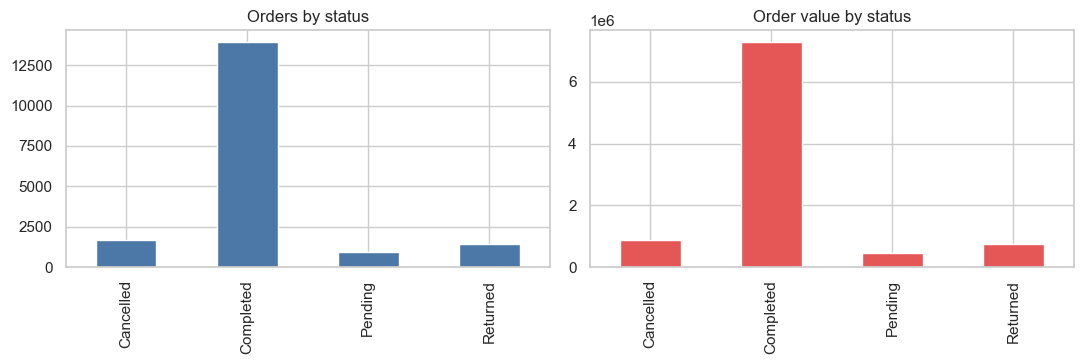

Pending orders older than 60 days: 760 orders, value 387,917 (a pending order that old is probably stuck)


In [58]:
status = df.groupby("status").agg(orders=("transaction_id", "count"), order_value=("net_sales", "sum"))
status["share_of_orders"] = status.orders / status.orders.sum(); status["share_of_value"] = status.order_value / status.order_value.sum()
display(status)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
status.orders.plot.bar(ax=ax[0], color="#4c78a8", title="Orders by status"); ax[0].set_xlabel("")
status.order_value.plot.bar(ax=ax[1], color="#e45756", title="Order value by status"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

old = df[(df.status == "Pending") & (df.timestamp < df.timestamp.max() - pd.Timedelta(days=60))]
print(f"Pending orders older than 60 days: {len(old)} orders, value {old.net_sales.sum():,.0f} (a pending order that old is probably stuck)")

**Write:** the share of value in Cancelled, Returned and Pending, and that old pending orders are stuck money.

## Step 4 · Time patterns
Questions: is there a trend or seasonality? Which days and hours are busy?

,orders,failed_rate,completed_sales,completed_profit,margin
month,,,,,
2025-01-01,1545,0.18,"631,337.30","178,488.70",0.28
2025-02-01,1380,0.18,"559,526.43","142,395.76",0.25
2025-03-01,1557,0.16,"633,536.51","179,674.60",0.28
2025-04-01,1446,0.18,"563,229.75","138,029.40",0.25
2025-05-01,1603,0.17,"679,623.53","199,515.32",0.29
2025-06-01,1431,0.17,"589,542.17","168,292.92",0.29
2025-07-01,1557,0.19,"663,235.42","165,097.48",0.25
2025-08-01,1560,0.17,"615,662.18","154,446.27",0.25
2025-09-01,1502,0.18,"594,603.85","156,755.69",0.26


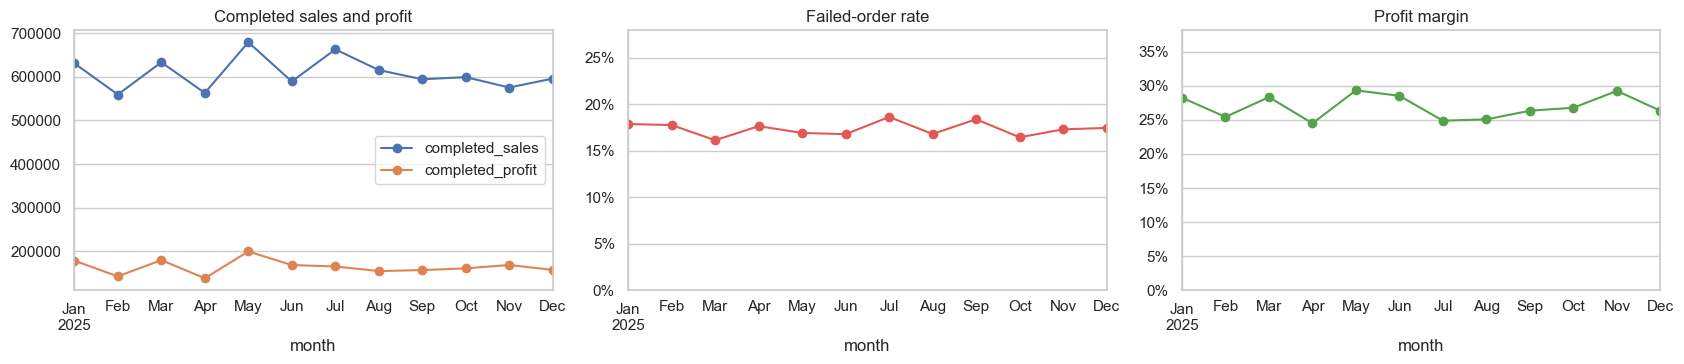

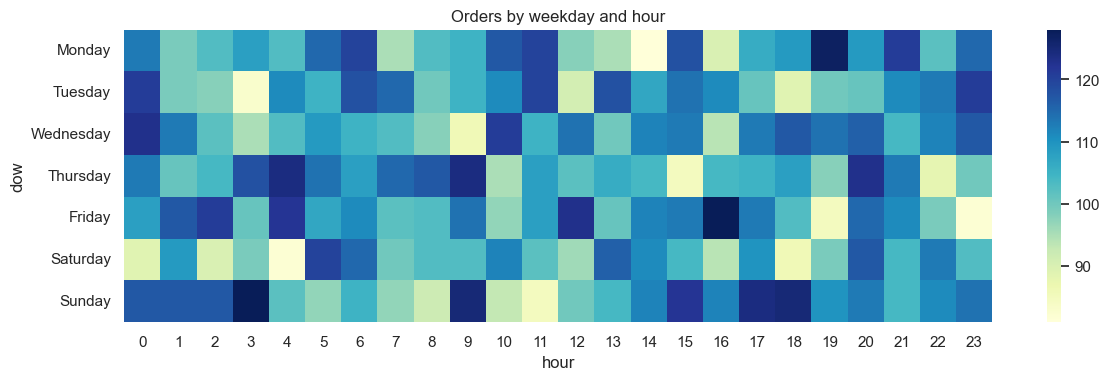

In [59]:
monthly = df.groupby("month").agg(orders=("transaction_id", "count"), failed_rate=("is_failed", "mean"))
monthly["completed_sales"] = comp.groupby("month").net_sales.sum(); monthly["completed_profit"] = comp.groupby("month").profit.sum()
monthly["margin"] = monthly.completed_profit / monthly.completed_sales
display(monthly)
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
monthly[["completed_sales", "completed_profit"]].plot(ax=ax[0], marker="o", title="Completed sales and profit")
monthly.failed_rate.plot(ax=ax[1], marker="o", color="#e45756", title="Failed-order rate"); ax[1].set_ylim(0, monthly.failed_rate.max()*1.5); ax[1].yaxis.set_major_formatter(pct)
monthly.margin.plot(ax=ax[2], marker="o", color="#54a24b", title="Profit margin"); ax[2].set_ylim(0, monthly.margin.max()*1.3); ax[2].yaxis.set_major_formatter(pct)
plt.tight_layout(); plt.show()

heat = df.pivot_table(index="dow", columns="hour", values="transaction_id", aggfunc="count").reindex(DOW)
plt.figure(figsize=(14, 3.8)); sns.heatmap(heat, cmap="YlGnBu"); plt.title("Orders by weekday and hour"); plt.show()

**Write:** whether sales trend up, down or flat; whether any month stands out; whether busy hours exist. If everything is flat, say so: that is a finding.

## Step 5 · Where do orders fail?
Question: do cancellations and returns concentrate in one channel, region, segment, category or payment method?
We use a **chi-square test**: a p-value above 0.05 means any gap is within random chance. Pending orders are excluded (outcome unknown).

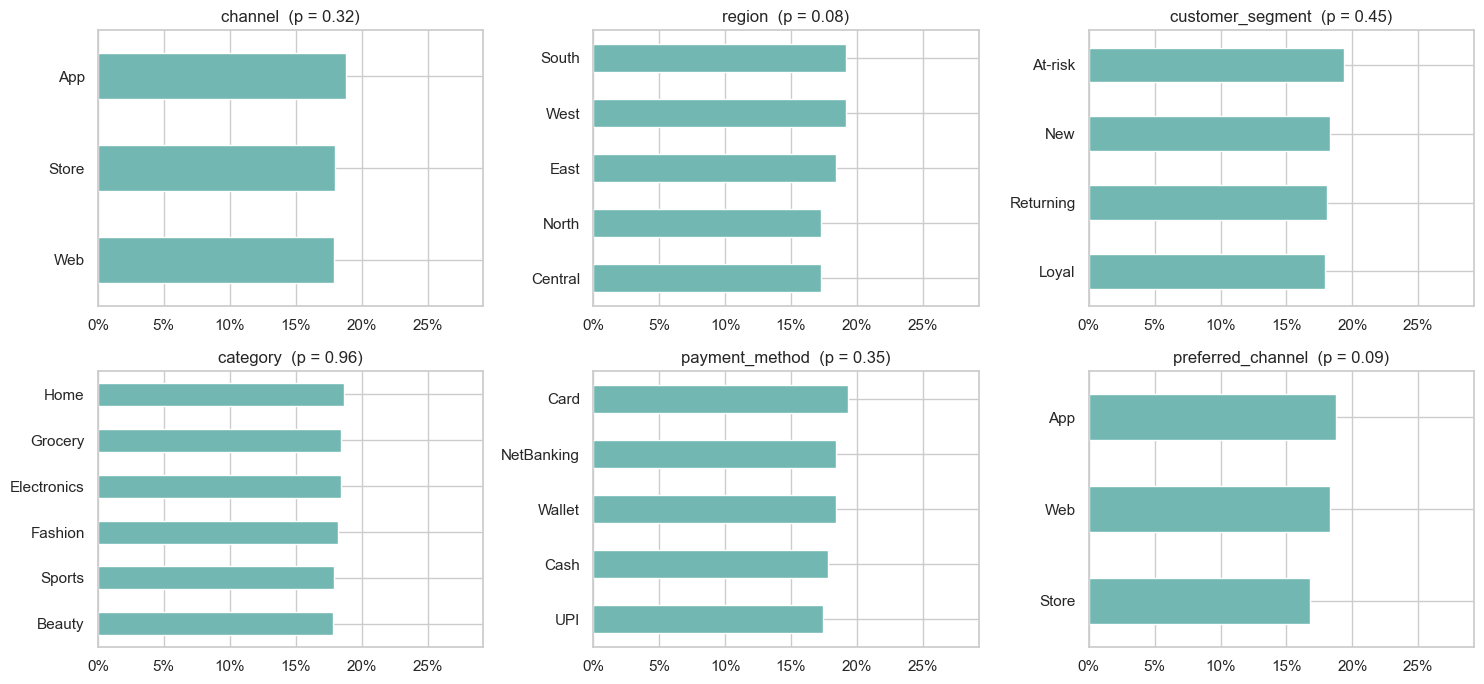

,dimension,highest group,highest rate,lowest rate,gap,chi2 p-value,verdict
0,channel,App,0.19,0.18,0.01,0.32,no clear cause
1,region,South,0.19,0.17,0.02,0.08,no clear cause
2,customer_segment,At-risk,0.19,0.18,0.01,0.45,no clear cause
3,category,Home,0.19,0.18,0.01,0.96,no clear cause
4,payment_method,Card,0.19,0.17,0.02,0.35,no clear cause
5,preferred_channel,App,0.19,0.17,0.02,0.09,no clear cause


Split of settled orders:


,share
status,
Completed,0.82
Cancelled,0.10
Returned,0.08


In [60]:
settled = df[df.status != "Pending"]
dims = ["channel", "region", "customer_segment", "category", "payment_method", "preferred_channel"]
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, dim in zip(axes.ravel(), dims):
    rate = settled.groupby(dim).is_failed.mean().sort_values()
    p = chi2_contingency(pd.crosstab(settled[dim], settled.is_failed))[1]
    rows.append((dim, rate.idxmax(), rate.max(), rate.min(), rate.max() - rate.min(), p, "clear difference" if p < 0.05 else "no clear cause"))
    rate.plot.barh(ax=ax, color="#72b7b2"); ax.set_title(f"{dim}  (p = {p:.2f})"); ax.set_xlim(0, settled.is_failed.mean()*1.6); ax.xaxis.set_major_formatter(pct); ax.set_ylabel("")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=["dimension", "highest group", "highest rate", "lowest rate", "gap", "chi2 p-value", "verdict"]))

print("Split of settled orders:"); display(settled.status.value_counts(normalize=True).to_frame("share"))

**Write:** the failure rate is about the same everywhere, so there is no single place to blame. This is an honest "no clear cause" result, backed by a test.

## Step 6 · Discounts
Question: do deeper discounts destroy profit?

,orders,net_sales,profit,loss_share,margin
discount_pct,,,,,
0.00,4804,"2,970,282.11","1,154,294.94",0.30,0.39
0.05,2113,"1,181,712.31","372,244.64",0.34,0.32
0.10,2785,"1,398,617.96","327,226.11",0.39,0.23
0.15,2121,"949,965.98","132,858.19",0.44,0.14
0.20,1426,"559,423.69","12,397.73",0.51,0.02
0.25,713,"241,696.21","-30,033.19",0.55,-0.12


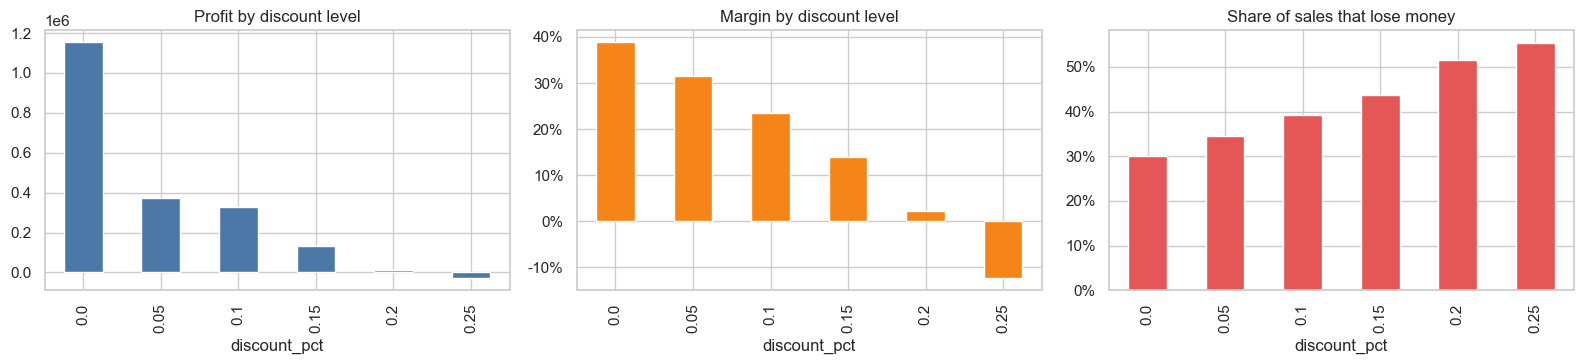

Do discounts change the failure rate?


,failed_rate
discount_pct,
0.00,0.18
0.05,0.17
0.10,0.18
0.15,0.17
0.20,0.16
0.25,0.17


Capping discounts at 10%: extra profit 174,148 (assumes the same orders still happen)
Capping discounts at 15%: extra profit 67,190 (assumes the same orders still happen)
Capping discounts at 20%: extra profit 16,113 (assumes the same orders still happen)


In [61]:
disc = comp.groupby("discount_pct").agg(orders=("profit", "size"), net_sales=("net_sales", "sum"), profit=("profit", "sum"), loss_share=("is_loss", "mean"))
disc["margin"] = disc.profit / disc.net_sales
display(disc)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
disc.profit.plot.bar(ax=ax[0], color="#4c78a8", title="Profit by discount level")
disc.margin.plot.bar(ax=ax[1], color="#f58518", title="Margin by discount level"); ax[1].yaxis.set_major_formatter(pct)
disc.loss_share.plot.bar(ax=ax[2], color="#e45756", title="Share of sales that lose money"); ax[2].yaxis.set_major_formatter(pct)
plt.tight_layout(); plt.show()

orders_by_disc = df.groupby("discount_pct").is_failed.mean()
print("Do discounts change the failure rate?"); display(orders_by_disc.to_frame("failed_rate"))
for cap in (0.10, 0.15, 0.20):
    gain = (comp.quantity * comp.unit_price * (comp.discount_pct - cap).clip(lower=0)).sum()
    print(f"Capping discounts at {cap:.0%}: extra profit {gain:,.0f} (assumes the same orders still happen)")

**Write:** margin falls as the discount rises and turns negative at the deepest level; the failure rate does not change with discount.

## Step 7 · Products and categories
Question: which products and categories make or lose money?

,orders,net_sales,profit,loss_share,margin,products_cost_above_list
category,,,,,,
Home,2436,"1,390,889.32","431,659.48",0.33,0.31,12
Electronics,2535,"1,316,100.72","412,263.67",0.38,0.31,12
Fashion,2016,"1,076,686.47","379,136.86",0.34,0.35,10
Sports,2374,"1,301,361.92","378,860.23",0.29,0.29,9
Grocery,2437,"1,282,925.56","300,332.44",0.41,0.23,15
Beauty,2164,"933,734.26","66,735.71",0.55,0.07,18


Products losing money overall: 94 of 250  | of those with cost above list price: 76
Loss on the cost-above-list products: 1,128,877 of total loss 1,214,116


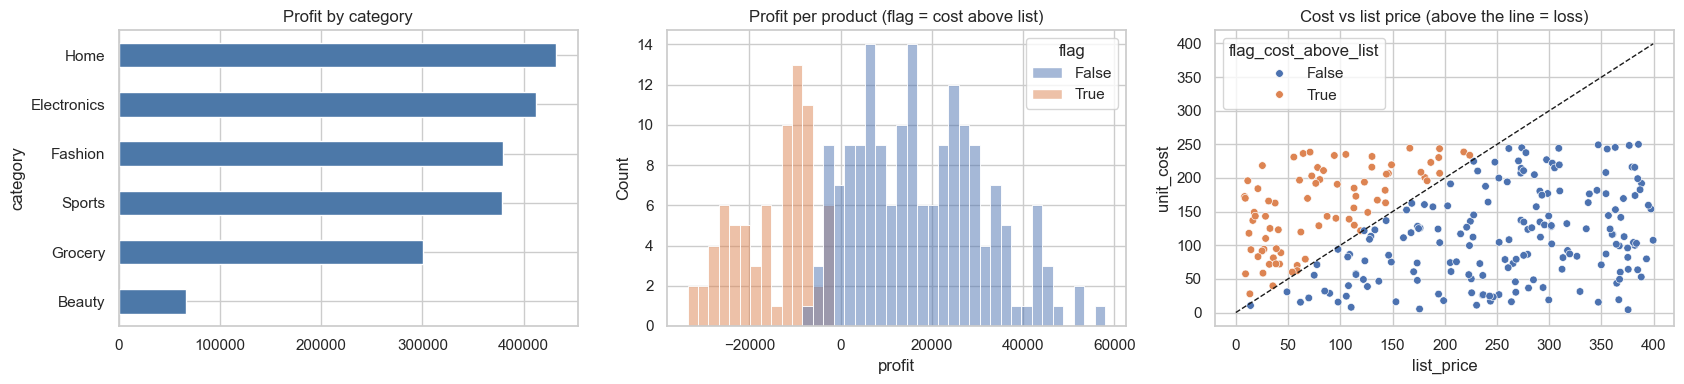

,product_id,category,orders,profit,net_sales,unit_cost,list_price,flag
191,PR0192,Grocery,68,"-33,514.73","6,101.91",165.76,31.41,True
162,PR0163,Electronics,55,"-32,633.35","10,056.36",238.49,71.06,True
209,PR0210,Sports,58,"-29,971.14","1,460.36",169.90,9.08,True
20,PR0021,Beauty,54,"-29,846.80","8,459.72",236.46,64.48,True
36,PR0037,Beauty,51,"-28,904.42","3,432.10",218.49,25.43,True
19,PR0020,Fashion,62,"-27,984.91","12,988.59",215.65,78.29,True
241,PR0242,Beauty,61,"-27,932.41","14,792.60",233.47,94.29,True
79,PR0080,Home,52,"-26,759.37","7,215.27",231.12,55.53,True
57,PR0058,Beauty,52,"-26,648.57","2,999.58",184.15,21.15,True
27,PR0028,Grocery,49,"-26,599.40","1,417.16",195.92,11.42,True


,product_id,category,orders,profit,net_sales,unit_cost,list_price,flag
100,PR0101,Home,70,"57,947.52","61,161.94",15.38,346.98,False
77,PR0078,Fashion,52,"53,033.83","53,726.05",4.17,375.47,False
23,PR0024,Electronics,59,"52,961.23","56,392.03",19.06,366.57,False
145,PR0146,Electronics,68,"48,250.89","54,348.54",31.27,329.44,False
15,PR0016,Grocery,62,"46,207.12","57,016.12",60.05,367.96,False


In [62]:
cat = comp.groupby("category").agg(orders=("profit", "size"), net_sales=("net_sales", "sum"), profit=("profit", "sum"), loss_share=("is_loss", "mean"))
cat["margin"] = cat.profit / cat.net_sales
products["flag_cost_above_list"] = products["unit_cost"] > products["list_price"]
comp["flag_cost_above_list"] = comp["product_id"].map(
    products.set_index("product_id")["flag_cost_above_list"]
)
cat["products_cost_above_list"] = (
    products.groupby("category")["flag_cost_above_list"].sum()
)
display(cat.sort_values("profit", ascending=False))

prod = comp.groupby(["product_id", "category"]).agg(orders=("profit", "size"), profit=("profit", "sum"), net_sales=("net_sales", "sum"),
                                                     unit_cost=("unit_cost", "first"), list_price=("list_price", "first"), flag=("flag_cost_above_list", "first")).reset_index()
print(f"Products losing money overall: {(prod.profit < 0).sum()} of {len(prod)}  | of those with cost above list price: {((prod.profit < 0) & prod.flag).sum()}")
print(f"Loss on the cost-above-list products: {-comp[comp.flag_cost_above_list].profit.sum():,.0f} of total loss {-comp[comp.is_loss].profit.sum():,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cat.profit.sort_values().plot.barh(ax=ax[0], color="#4c78a8", title="Profit by category")
sns.histplot(data=prod, x="profit", hue="flag", bins=40, ax=ax[1]); ax[1].set_title("Profit per product (flag = cost above list)")
sns.scatterplot(data=products, x="list_price", y="unit_cost", hue="flag_cost_above_list", ax=ax[2], s=30)
ax[2].plot([0, products.list_price.max()], [0, products.list_price.max()], "k--", lw=1); ax[2].set_title("Cost vs list price (above the line = loss)")
plt.tight_layout(); plt.show()
display(prod.sort_values("profit").head(10)); display(prod.sort_values("profit", ascending=False).head(5))

**Write:** one group of products (cost above list price) causes almost all of the loss. Beauty is the weakest category: lowest margin, highest share of losing sales, and the most cost-above-list products.

## Step 8 · Customers
Questions: which segments and regions earn the most? How often do customers buy? Do orders dated before signup behave differently?

,customers,orders,profit,avg_order_profit
customer_segment,,,,
At-risk,444,2088,"273,002.45",130.75
Loyal,723,3371,"473,793.57",140.55
New,764,3609,"543,535.25",150.61
Returning,1040,4894,"678,657.14",138.67


,customers,orders,profit,avg_order_profit
region,,,,
Central,552,2659,"376,031.68",141.42
East,588,2700,"381,554.08",141.32
North,630,3073,"414,829.35",134.99
South,572,2654,"371,077.27",139.82
West,629,2876,"425,496.02",147.95


Orders per customer: mean 6.0, min 1, max 16
Customers with negative total profit: 23.6%
Top 10% of customers earn 33% of all positive profit


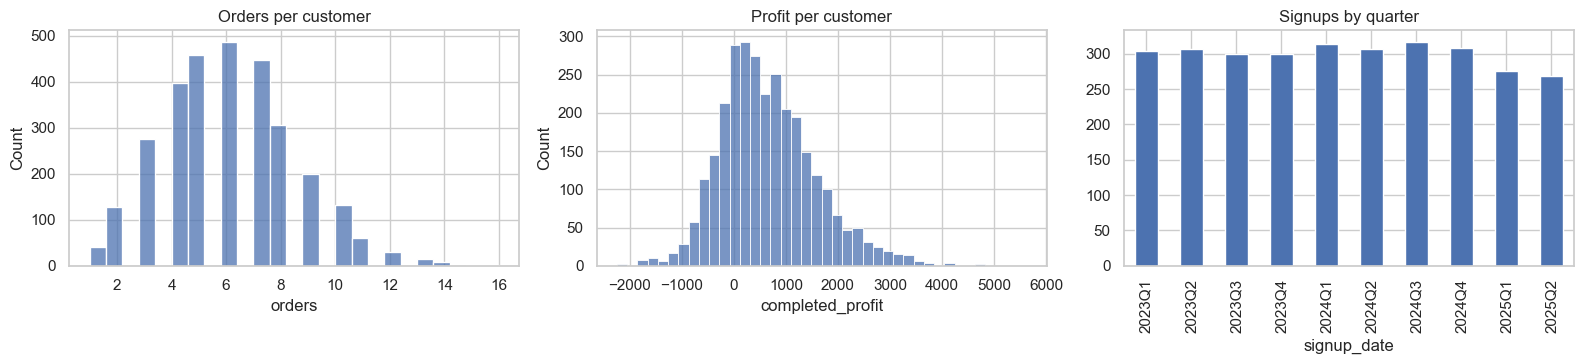

,orders,failed_rate,loss_share,avg_net_sales
flag_before_signup,,,,
False,17203,0.17,0.29,521.28
True,797,0.17,0.30,531.07


Failed-rate difference for before-signup orders: p = 0.72 -> no clear difference, safe to keep


In [63]:
seg = comp.groupby("customer_segment").agg(customers=("customer_id", "nunique"), orders=("profit", "size"), profit=("profit", "sum"), avg_order_profit=("profit", "mean"))
reg = comp.groupby("region").agg(customers=("customer_id", "nunique"), orders=("profit", "size"), profit=("profit", "sum"), avg_order_profit=("profit", "mean"))
display(seg); display(reg)

per = df.groupby("customer_id").agg(orders=("transaction_id", "count"), completed_profit=("profit", lambda s: s[df.loc[s.index, "is_completed"]].sum()))
print(f"Orders per customer: mean {per.orders.mean():.1f}, min {per.orders.min()}, max {per.orders.max()}")
print(f"Customers with negative total profit: {(per.completed_profit < 0).mean():.1%}")
top10 = per.completed_profit.sort_values(ascending=False).head(int(len(per) * 0.1)).sum() / per.completed_profit[per.completed_profit > 0].sum()
print(f"Top 10% of customers earn {top10:.0%} of all positive profit")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(per.orders, bins=25, ax=ax[0]); ax[0].set_title("Orders per customer")
sns.histplot(per.completed_profit, bins=40, ax=ax[1]); ax[1].set_title("Profit per customer")
customers.groupby(customers.signup_date.dt.to_period("Q").astype(str)).size().plot.bar(ax=ax[2], title="Signups by quarter")
plt.tight_layout(); plt.show()

# orders dated before signup (flagged in cleaning)
df["flag_before_signup"] = df["tenure_days"] < 0

cmp = df.groupby("flag_before_signup").agg(
    orders=("transaction_id", "count"),
    failed_rate=("is_failed", "mean"),
    loss_share=("is_loss", "mean"),
    avg_net_sales=("net_sales", "mean"),
)

settled = df[df["status"] != "Pending"].copy()
display(cmp)
p = chi2_contingency(pd.crosstab(settled.flag_before_signup, settled.is_failed))[1]
print(f"Failed-rate difference for before-signup orders: p = {p:.2f} ->", "no clear difference, safe to keep" if p >= 0.05 else "differs, treat with care")

**Write:** which segment is most valuable, how concentrated profit is, and that before-signup orders behave like the rest.

## Step 9 · Channels
Questions: how do App, Web and Store compare? Do customers buy on their preferred channel?
Remember: orders exist only for App, Web and Store. Social and Email appear only in advertising.

,orders,failed_rate,completed_sales,completed_profit,margin,avg_discount
channel,,,,,,
App,7115,0.18,"2,829,459.48","742,581.55",0.26,0.08
Store,2793,0.17,"1,151,746.67","331,303.86",0.29,0.08
Web,8092,0.17,"3,320,492.10","895,102.99",0.27,0.08


Orders placed on the customer's preferred channel: 38%   (random chance with 3 channels would be about 33%)


channel,App,Store,Web
preferred_channel,,,
App,0.39,0.16,0.45
Store,0.39,0.15,0.46
Web,0.40,0.15,0.45


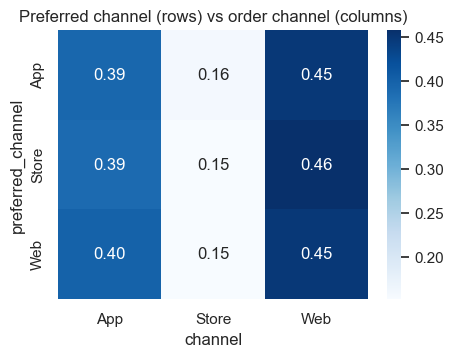

In [64]:
chn = df.groupby("channel").agg(orders=("transaction_id", "count"), failed_rate=("is_failed", "mean"))
chn["completed_sales"] = comp.groupby("channel").net_sales.sum(); chn["completed_profit"] = comp.groupby("channel").profit.sum()
chn["margin"] = chn.completed_profit / chn.completed_sales; chn["avg_discount"] = df.groupby("channel").discount_pct.mean()
display(chn)

match = (df.channel == df.preferred_channel).mean()
print(f"Orders placed on the customer's preferred channel: {match:.0%}   (random chance with 3 channels would be about 33%)")
display(pd.crosstab(df.preferred_channel, df.channel, normalize="index").round(3))
plt.figure(figsize=(5, 3.5)); sns.heatmap(pd.crosstab(df.preferred_channel, df.channel, normalize="index"), annot=True, fmt=".2f", cmap="Blues")
plt.title("Preferred channel (rows) vs order channel (columns)"); plt.show()

**Write:** channels perform about the same. The 38% match is just the overall channel mix (Web and App dominate, Store is smaller). Every preference group orders in the same proportions, so `preferred_channel` carries no information.

## Step 10 · Marketing
Questions: which ad categories and channels give the best return? Is spend related to results?
Impossible rows (flagged in cleaning) are excluded.
**ROAS** (return on ad spend) = completed sales in a category per 1 unit of valid ad spend.
Campaigns cannot be linked to single orders, so this is a category-level comparison only.

Valid campaign rows: 1029 of 1200  | valid spend 4,130,514 of 4,805,016


,valid_spend,ctr,cvr,cost_per_conv,completed_sales,roas
category,,,,,,
Home,"673,056.60",0.14,0.23,5.53,"1,390,889.32",2.07
Sports,"647,101.99",0.15,0.18,6.37,"1,301,361.92",2.01
Grocery,"679,156.49",0.16,0.18,5.04,"1,282,925.56",1.89
Electronics,"705,595.90",0.17,0.18,5.78,"1,316,100.72",1.87
Fashion,"687,372.14",0.16,0.19,5.67,"1,076,686.47",1.57
Beauty,"738,230.43",0.18,0.21,5.42,"933,734.26",1.26


,valid_spend,ctr,cvr,cost_per_conv
channel,,,,
App,"888,175.85",0.16,0.19,4.97
Email,"744,969.90",0.16,0.20,5.76
Social,"863,533.98",0.17,0.20,5.60
Store,"860,197.02",0.15,0.19,5.89
Web,"773,636.80",0.16,0.20,5.27


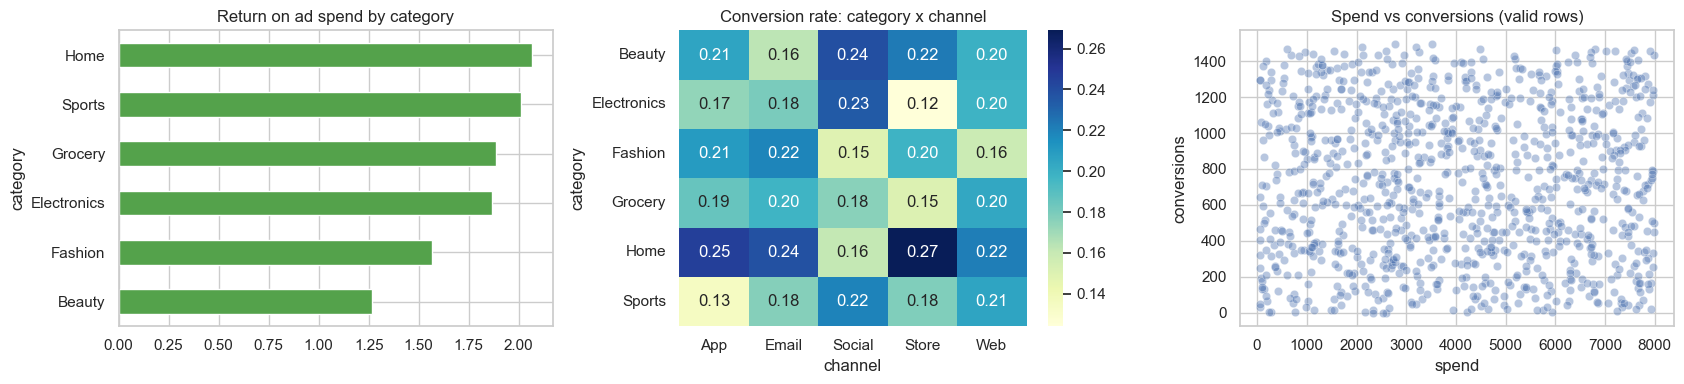

Correlation spend vs conversions: -0.01   spend vs clicks: 0.00


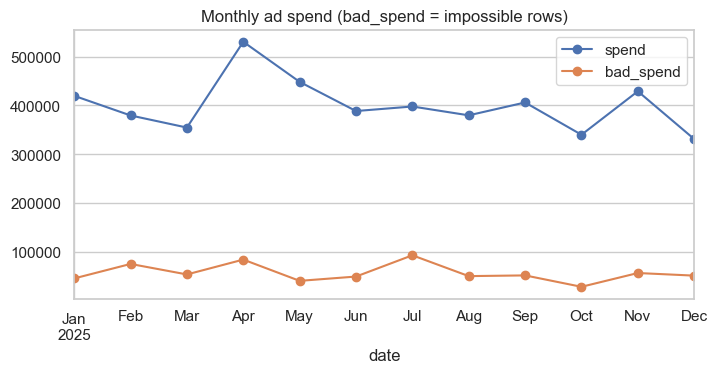

In [65]:
campaigns["flag_impossible"] = (
    (campaigns["clicks"] > campaigns["impressions"])
    | (campaigns["conversions"] > campaigns["clicks"])
    | (campaigns["spend"] < 0)
)

campaigns["ctr"] = campaigns["clicks"].div(
    campaigns["impressions"].replace(0, np.nan)
)
campaigns["cvr"] = campaigns["conversions"].div(
    campaigns["clicks"].replace(0, np.nan)
)
campaigns["cost_per_conversion"] = campaigns["spend"].div(
    campaigns["conversions"].replace(0, np.nan)
)

ok = campaigns[~campaigns["flag_impossible"]].copy()
print(f"Valid campaign rows: {len(ok)} of {len(campaigns)}  | valid spend {ok.spend.sum():,.0f} of {campaigns.spend.sum():,.0f}")

by_cat = ok.groupby("category").agg(valid_spend=("spend", "sum"), ctr=("ctr", "mean"), cvr=("cvr", "mean"), cost_per_conv=("cost_per_conversion", "median"))
by_cat["completed_sales"] = comp.groupby("category").net_sales.sum(); by_cat["roas"] = by_cat.completed_sales / by_cat.valid_spend
display(by_cat.sort_values("roas", ascending=False))
by_ch = ok.groupby("channel").agg(valid_spend=("spend", "sum"), ctr=("ctr", "mean"), cvr=("cvr", "mean"), cost_per_conv=("cost_per_conversion", "median"))
display(by_ch)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
by_cat.roas.sort_values().plot.barh(ax=ax[0], color="#54a24b", title="Return on ad spend by category")
sns.heatmap(ok.pivot_table(index="category", columns="channel", values="cvr", aggfunc="mean"), annot=True, fmt=".2f", cmap="YlGnBu", ax=ax[1]); ax[1].set_title("Conversion rate: category x channel")
sns.scatterplot(data=ok, x="spend", y="conversions", alpha=.4, ax=ax[2]); ax[2].set_title("Spend vs conversions (valid rows)")
plt.tight_layout(); plt.show()
print("Correlation spend vs conversions: %.2f   spend vs clicks: %.2f" % (ok.spend.corr(ok.conversions), ok.spend.corr(ok.clicks)))
spend_m = campaigns.groupby(campaigns.date.dt.to_period("M").dt.to_timestamp()).agg(spend=("spend", "sum"), bad_spend=("spend", lambda s: s[campaigns.loc[s.index, "flag_impossible"]].sum()))
spend_m.plot(marker="o", figsize=(8, 3.5), title="Monthly ad spend (bad_spend = impossible rows)"); plt.show()

**Write:** which categories return the most per unit of spend, which return the least, and that spend alone does not predict conversions (correlation near 0).

## Step 11 · Inventory
Questions: how common are low stock and supplier delays? Is the stockout flag reliable?

Stockout-flag rate: 15.2% | below reorder level: 14.0% | supplier delay > 14 days: 26.2%
Flagged as stockout but stock > 0: 760 of 760
Mean values by flag:


,stock_on_hand,reorder_threshold,supplier_delay_days
stockout_flag,,,
0,151.30,44.64,9.65
1,155.05,45.29,9.57


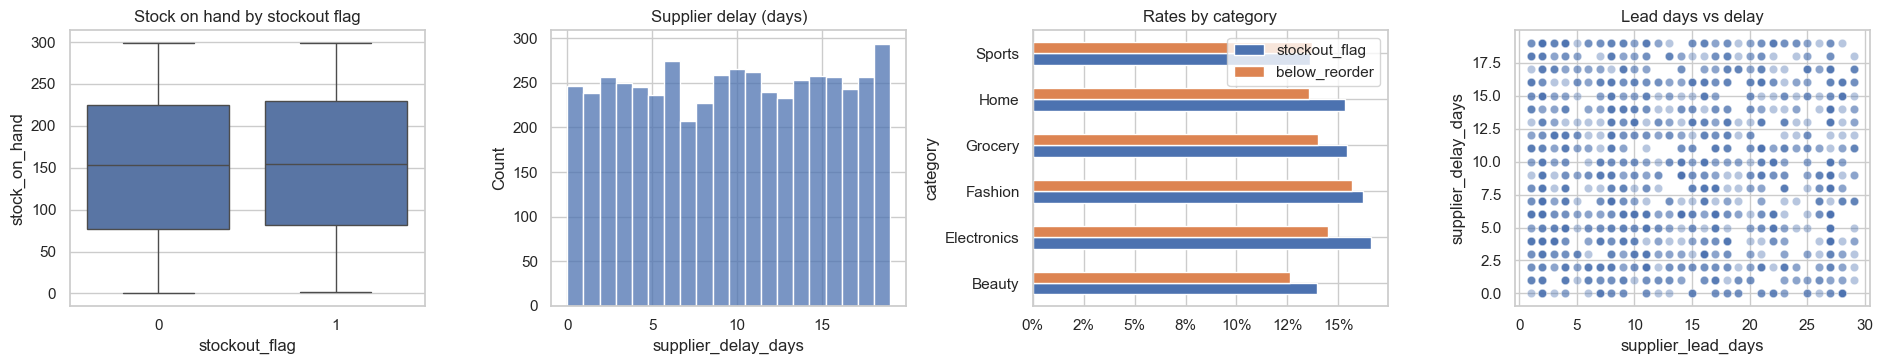

Days of stock cover (latest record per product):


,count,mean,std,min,25%,50%,75%,max
days_cover,250.00,320.87,201.00,4.26,171.07,284.36,463.29,863.37


,product_id,category,stock_on_hand,reorder_threshold,daily_sales,days_cover
3811,PR0039,Grocery,2,55,0.47,4.26
2562,PR0071,Electronics,3,12,0.50,6.00
4780,PR0239,Grocery,3,66,0.50,6.03
3931,PR0132,Electronics,3,45,0.45,6.62
4755,PR0166,Beauty,4,34,0.52,7.74
4115,PR0184,Electronics,5,71,0.54,9.29
1153,PR0010,Beauty,5,10,0.53,9.48
654,PR0211,Fashion,10,42,0.57,17.42


In [66]:
inv = inventory.merge(products[["product_id", "category", "supplier_lead_days"]], on="product_id")
inv["below_reorder"] = inv["stock_on_hand"] < inv["reorder_threshold"]
inv["flag_stockout_contradiction"] = (
    inv["stockout_flag"].eq(1) & inv["stock_on_hand"].gt(0)
)

print(f"Stockout-flag rate: {inv.stockout_flag.mean():.1%} | below reorder level: {inv.below_reorder.mean():.1%} | supplier delay > 14 days: {(inv.supplier_delay_days > 14).mean():.1%}")
print(f"Flagged as stockout but stock > 0: {inv.flag_stockout_contradiction.sum()} of {int(inv.stockout_flag.sum())}")
print("Mean values by flag:"); display(inv.groupby("stockout_flag")[["stock_on_hand", "reorder_threshold", "supplier_delay_days"]].mean())

fig, ax = plt.subplots(1, 4, figsize=(19, 3.8))
sns.boxplot(data=inv, x="stockout_flag", y="stock_on_hand", ax=ax[0]); ax[0].set_title("Stock on hand by stockout flag")
sns.histplot(inv.supplier_delay_days, bins=20, ax=ax[1]); ax[1].set_title("Supplier delay (days)")
inv.groupby("category")[["stockout_flag", "below_reorder"]].mean().plot.barh(ax=ax[2], title="Rates by category"); ax[2].xaxis.set_major_formatter(pct)
sns.scatterplot(data=inv.sample(1500, random_state=0), x="supplier_lead_days", y="supplier_delay_days", alpha=.4, ax=ax[3]); ax[3].set_title("Lead days vs delay")
plt.tight_layout(); plt.show()

days = max((df.timestamp.max() - df.timestamp.min()).days, 1)
latest = inv.sort_values("date").groupby("product_id").tail(1).copy()
latest["daily_sales"] = latest.product_id.map(comp.groupby("product_id").quantity.sum() / days)
latest["days_cover"] = latest.stock_on_hand / latest.daily_sales.replace(0, np.nan)
print("Days of stock cover (latest record per product):"); display(latest.days_cover.describe().to_frame("days_cover").T)
display(latest.sort_values("days_cover").head(8)[["product_id", "category", "stock_on_hand", "reorder_threshold", "daily_sales", "days_cover"]])

**Write:** the stockout flag does not match stock levels, so we use real numbers (below reorder level, days of cover) to find stock risk instead.

## Step 12 · Correlations
Question: which numeric columns move together?

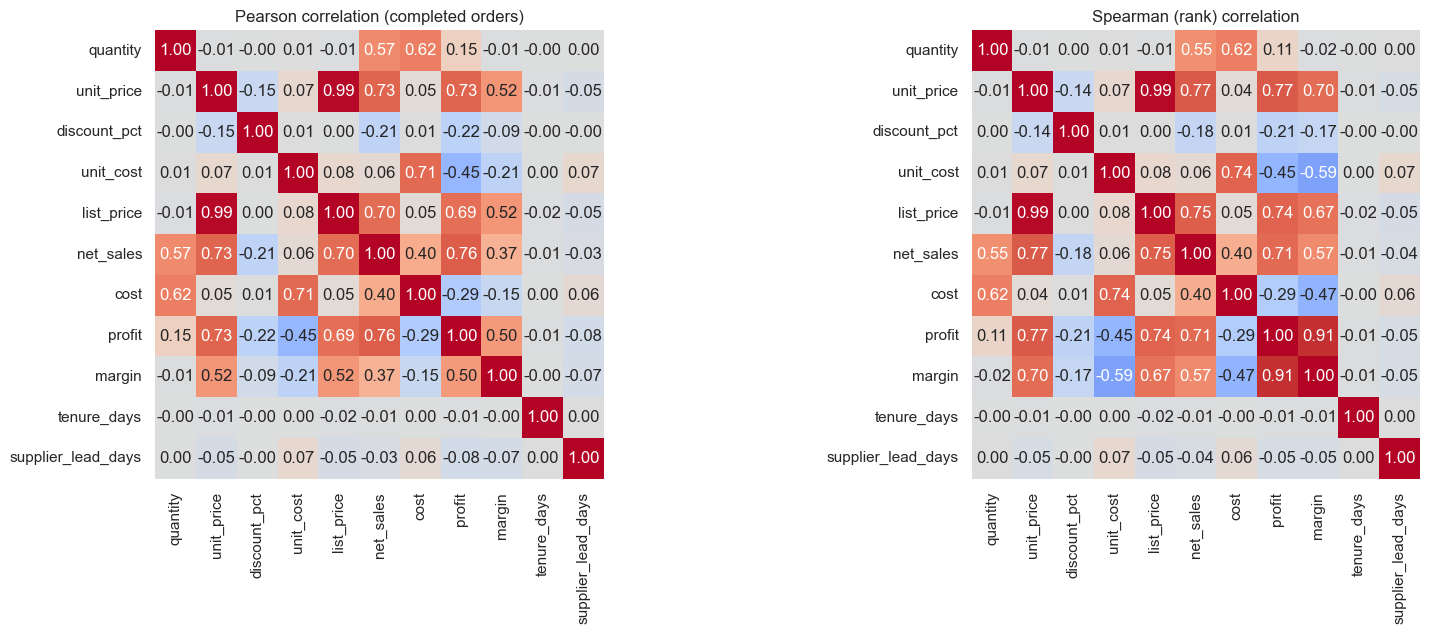

Correlation of each column with profit:


,corr_with_profit
unit_cost,-0.45
cost,-0.29
discount_pct,-0.22
supplier_lead_days,-0.08
tenure_days,-0.01
quantity,0.15
margin,0.50
list_price,0.69
unit_price,0.73
net_sales,0.76


In [67]:
num = comp[["quantity", "unit_price", "discount_pct", "unit_cost", "list_price", "net_sales", "cost", "profit", "margin", "tenure_days", "supplier_lead_days"]]
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax[0], cbar=False); ax[0].set_title("Pearson correlation (completed orders)")
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax[1], cbar=False); ax[1].set_title("Spearman (rank) correlation")
plt.tight_layout(); plt.show()
print("Correlation of each column with profit:"); display(num.corr()["profit"].drop("profit").sort_values().to_frame("corr_with_profit"))

**Write:** profit is driven by cost and discount, not by customer tenure or quantity. Correlation shows a link, not a cause.

## Step 13 · Summary of findings
These lines are computed from your own data, so they update if the data changes. Copy them into your report.

In [68]:
lost = -comp[comp.is_loss].profit.sum(); lost_flag = -comp[comp.flag_cost_above_list].profit.sum()
sp = df[df.status != "Pending"]; gap = max(sp.groupby(d).is_failed.mean().max() - sp.groupby(d).is_failed.mean().min() for d in ["channel", "region", "customer_segment", "category"])
print("KEY FINDINGS")
print(f"1. {df[~df.is_completed].net_sales.sum()/df.net_sales.sum():.0%} of order value never became a completed sale (cancelled {status.loc['Cancelled','share_of_value']:.0%}, returned {status.loc['Returned','share_of_value']:.0%}, pending {status.loc['Pending','share_of_value']:.0%}).")
print(f"2. {comp.is_loss.mean():.0%} of completed sales lose money; {lost:,.0f} lost, of which {lost_flag:,.0f} ({lost_flag/lost:.0%}) is on products whose cost is above list price.")
print(f"3. Failed-order rate differs by at most {gap:.1%} across channel, region, segment and category; chi-square tests find no clear cause.")
print(f"4. Margin is {disc.margin.iloc[0]:.0%} with no discount and {disc.margin.iloc[-1]:.0%} at a {disc.index[-1]:.0%} discount.")
print(f"5. Ad spend on impossible campaign rows: {campaigns[campaigns.flag_impossible].spend.sum():,.0f} ({campaigns.flag_impossible.sum()} rows). Best return: {by_cat.roas.idxmax()} ({by_cat.roas.max():.2f}); weakest: {by_cat.roas.idxmin()} ({by_cat.roas.min():.2f}).")
print(f"6. The stockout flag is unreliable ({inv.flag_stockout_contradiction.sum()} of {int(inv.stockout_flag.sum())} flags have stock on hand). {inv.below_reorder.mean():.0%} of records are below the reorder level.")
b = cat.loc["Beauty"]
print(f"7. Beauty is weakest on both fronts: margin {b.margin:.0%} (others {cat.drop('Beauty').margin.min():.0%} to {cat.drop('Beauty').margin.max():.0%}) and the lowest ad return ({by_cat.roas['Beauty']:.2f}).")
print(f"8. Orders come only from App, Web and Store; Social and Email exist only in advertising.")

KEY FINDINGS
1. 22% of order value never became a completed sale (cancelled 9%, returned 8%, pending 5%).
2. 38% of completed sales lose money; 1,214,116 lost, of which 1,128,877 (93%) is on products whose cost is above list price.
3. Failed-order rate differs by at most 1.9% across channel, region, segment and category; chi-square tests find no clear cause.
4. Margin is 39% with no discount and -12% at a 25% discount.
5. Ad spend on impossible campaign rows: 674,503 (171 rows). Best return: Home (2.07); weakest: Beauty (1.26).
6. The stockout flag is unreliable (760 of 760 flags have stock on hand). 14% of records are below the reorder level.
7. Beauty is weakest on both fronts: margin 7% (others 23% to 35%) and the lowest ad return (1.26).
8. Orders come only from App, Web and Store; Social and Email exist only in advertising.
